# Clasificador de mensajes de clientes con Qwen2.5-1.5B + LoRA

**Objetivo:** clasificar mensajes en `pedido`, `devolucion`, `queja` u `otro`, comparar el modelo antes y después del ajuste y publicar el adaptador LoRA en Hugging Face Hub.

- Modelo base: [`Qwen/Qwen2.5-1.5B-Instruct`](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct)
- Dataset sintético: 300 mensajes (75 por categoría).
- División estratificada: 250 entrenamiento + 50 prueba.
- Entrenamiento: LoRA con PEFT.
- Evaluación: mismos 50 mensajes antes y después.

> **Importante:** los ejemplos se generan de forma reproducible a partir de plantillas. Revísalos manualmente y modifica los textos si hace falta antes de entrenar. No introduzcas datos personales reales. El conjunto sintético sirve para la práctica, no sustituye un dataset real de producción.

## 1. Configurar Colab con GPU

En Colab: **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU**. Empieza con la opción gratuita; no necesitas contratar Colab Pro para intentar esta práctica. La disponibilidad de GPU no está garantizada y varía según el uso y los recursos disponibles.

Ejecuta la siguiente celda. Si no aparece una GPU NVIDIA, cambia el tipo de entorno de ejecución a GPU y vuelve a ejecutarla.

In [ ]:
import torch, os, platform
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))
else:
    raise RuntimeError("No hay GPU activa. En Colab selecciona Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU.")

Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA disponible: True
GPU: Tesla T4
VRAM (GB): 15.64


## 2. Instalar librerías
Usamos `transformers`, `datasets` y `peft`, además de las librerías de evaluación.

In [ ]:
import transformers, datasets, peft, pandas as pd, numpy as np
print("transformers:", transformers.__version__)
print("datasets:", datasets.__version__)
print("peft:", peft.__version__)

transformers: 4.48.3
datasets: 3.2.0
peft: 0.14.0


## 3. Conectar con Hugging Face Hub

Como ya tienes cuenta, crea un **User Access Token** en [Hugging Face → Settings → Access Tokens](https://huggingface.co/settings/tokens). Necesita permiso de escritura para publicar el modelo.

En Colab abre el panel izquierdo **Secrets** (icono de llave), crea un secreto llamado `HF_TOKEN`, pega allí el token y activa el acceso para este notebook. No escribas el token directamente en una celda ni lo compartas.

In [ ]:
from google.colab import userdata
from huggingface_hub import login

HF_TOKEN = userdata.get("HF_TOKEN")
if not HF_TOKEN:
    raise ValueError("Crea el secreto HF_TOKEN en Colab > Secrets y habilita su acceso para este notebook.")
login(token=HF_TOKEN, add_to_git_credential=False)
print("Autenticación correcta.")

Autenticación correcta.


## 4. Definir el modelo y las categorías

El modelo tiene 1.54B parámetros y la ficha oficial indica soporte multilingüe, incluido español. Usaremos el modelo instruct y le pediremos una sola etiqueta por mensaje.

Definición de etiquetas para evitar ambigüedades:
- `pedido`: compra, estado, seguimiento o modificación de un pedido.
- `devolucion`: devolución, cambio, reembolso o desistimiento.
- `queja`: insatisfacción o reclamación sobre producto/servicio, sin que la intención principal sea devolver.
- `otro`: consultas generales que no encajan en las anteriores.

In [ ]:
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
LABELS = ["pedido", "devolucion", "queja", "otro"]

## 5. Crear 300 ejemplos sintéticos equilibrados

La celda crea 75 mensajes por categoría (15 situaciones × 5 formulaciones). Son datos sintéticos, sin información personal real. Después podrás exportarlos a CSV, inspeccionarlos y corregirlos antes de continuar.

In [10]:
import itertools, random
from datasets import Dataset

random.seed(42)

scenarios = {
    "pedido": [
        "consultar si el pedido #A104 ya ha salido del almacén",
        "saber cuándo llegará la compra realizada ayer",
        "cambiar la dirección de entrega de un pedido en curso",
        "añadir una unidad más al pedido #B208",
        "confirmar si se ha recibido correctamente el pedido",
        "conocer el número de seguimiento del paquete",
        "preguntar si el pedido puede llegar antes del viernes",
        "comprobar qué productos incluye el pedido #C315",
        "solicitar una factura de la compra",
        "saber por qué el pedido figura todavía como preparando",
        "corregir el teléfono asociado a la entrega",
        "consultar si se puede modificar la talla antes del envío",
        "confirmar la fecha estimada de entrega",
        "preguntar si el pago del pedido se ha registrado",
        "consultar el estado de un pedido que aparece como enviado"
    ],
    "devolucion": [
        "devolver una camiseta porque no me queda bien",
        "solicitar el reembolso de unos zapatos",
        "cambiar un producto por otra talla",
        "iniciar la devolución de un artículo comprado online",
        "saber cuántos días tengo para devolver una compra",
        "devolver un producto que finalmente no necesito",
        "recibir el dinero de una compra cancelada",
        "cambiar el color del artículo por otro disponible",
        "obtener una etiqueta para enviar el producto de vuelta",
        "consultar si los gastos de devolución son gratuitos",
        "devolver dos artículos del mismo pedido",
        "solicitar un cambio porque el producto es demasiado grande",
        "conocer cuándo se abonará el importe de la devolución",
        "cancelar la compra y recuperar el dinero",
        "preguntar cómo ejercer el derecho de desistimiento"
    ],
    "queja": [
        "expresar mi enfado por la mala atención recibida",
        "informar de que el repartidor fue muy poco amable",
        "quejarme porque el producto llegó con un defecto y quiero dejar constancia",
        "denunciar que llevo días sin recibir respuesta del servicio de atención",
        "indicar que la calidad del artículo es decepcionante",
        "mostrar mi descontento por una experiencia de compra muy mala",
        "reclamar por el trato recibido en la tienda",
        "comunicar que la web falla continuamente al intentar comprar",
        "quejarme por recibir información contradictoria del soporte",
        "dejar constancia de que el embalaje llegó destrozado",
        "expresar mi insatisfacción con la reparación realizada",
        "reclamar porque el servicio prometido no se prestó",
        "indicar que el producto anunciado no se corresponde con la realidad",
        "quejarme por la espera excesiva en atención al cliente",
        "solicitar que registren mi reclamación por el mal servicio"
    ],
    "otro": [
        "preguntar cuál es el horario de atención al cliente",
        "saber si la tienda abre los domingos",
        "consultar qué métodos de pago se aceptan en general",
        "preguntar si existe un programa de puntos",
        "conocer dónde están ubicadas las tiendas físicas",
        "solicitar información sobre la política de privacidad",
        "preguntar si ofrecen envoltorio para regalo",
        "saber cómo suscribirme al boletín de novedades",
        "consultar si hay descuentos para estudiantes",
        "preguntar qué materiales se utilizan en los productos",
        "conocer si la empresa tiene catálogo en papel",
        "solicitar información sobre oportunidades de empleo",
        "preguntar cómo contactar con el departamento comercial",
        "saber si la tienda dispone de aparcamiento",
        "consultar si se puede comprar una tarjeta regalo"
    ]
}

wrappers = {
    "pedido": [
        "Hola, necesito {s}. ¿Podéis ayudarme?",
        "Buenas, quisiera {s}. Gracias.",
        "Tengo una consulta: necesito {s}.",
        "Por favor, ¿me podéis indicar cómo puedo {s}?",
        "Os escribo porque quiero {s}. Un saludo."
    ],
    "devolucion": [
        "Hola, necesito gestionar lo siguiente: {s}.",
        "Buenas, ¿podéis ayudarme a {s}?",
        "Quiero tramitar una gestión porque necesito {s}.",
        "Por favor, indicadme los pasos para {s}.",
        "Me gustaría resolver esto: necesito {s}. Gracias."
    ],
    "queja": [
        "Quiero presentar una queja: {s}.",
        "Estoy bastante descontento porque necesito {s}.",
        "Os escribo para dejar constancia de que quiero {s}.",
        "Mi experiencia ha sido negativa: {s}.",
        "Necesito trasladar mi malestar: {s}."
    ],
    "otro": [
        "Hola, tengo una duda general: {s}.",
        "Buenas, ¿me podéis informar sobre esto? Quiero {s}.",
        "Necesito información, concretamente quiero {s}.",
        "Una consulta: ¿podríais ayudarme a {s}?",
        "Quisiera saber algo sobre la empresa: {s}. Gracias."
    ]
}

rows = []
for label, items in scenarios.items():
    for i, (scenario, wrapper) in enumerate(itertools.product(items, wrappers[label])):
        rows.append({
            "mensaje": wrapper.format(s=scenario),
            "categoria": label,
            "grupo": f"{label}_{i // len(wrappers[label])}"
        })

random.Random(42).shuffle(rows)
df = pd.DataFrame(rows)
assert len(df) == 300
assert df["categoria"].value_counts().to_dict() == {k: 75 for k in LABELS}
assert df["mensaje"].is_unique

print("Total:", len(df))
display(df.groupby("categoria").size().rename("mensajes").to_frame())
display(df.groupby("categoria").head(3))

Total: 300


,mensajes
categoria,
devolucion,75
otro,75
pedido,75
queja,75


,mensaje,categoria,grupo
0,"Buenas, ¿podéis ayudarme a recibir el dinero d...",devolucion,devolucion_6
1,Quisiera saber algo sobre la empresa: consulta...,otro,otro_2
2,Tengo una consulta: necesito comprobar qué pro...,pedido,pedido_7
3,Me gustaría resolver esto: necesito cambiar un...,devolucion,devolucion_2
4,Tengo una consulta: necesito preguntar si el p...,pedido,pedido_6
5,"Hola, tengo una duda general: solicitar inform...",otro,otro_5
6,Os escribo para dejar constancia de que quiero...,queja,queja_8
7,"Hola, necesito gestionar lo siguiente: consult...",devolucion,devolucion_9
8,Os escribo porque quiero añadir una unidad más...,pedido,pedido_3
9,"Hola, tengo una duda general: preguntar cuál e...",otro,otro_0


### Revisión manual obligatoria

Antes de entrenar, inspecciona los mensajes. Puedes descargar el CSV, editarlo en una hoja de cálculo y volver a cargarlo. Mantén exactamente 75 ejemplos por categoría y no uses los mensajes de prueba para ajustar el entrenamiento.

Si editas el CSV, súbelo con el panel Files de Colab y ejecuta la siguiente celda con `CARGAR_CSV = True`.

In [ ]:
CARGAR_CSV = False  # Cambia a True si has subido y revisado mensajes_clientes_300.csv
if CARGAR_CSV:
    from google.colab import files
    uploaded = files.upload()
    nombre = next(iter(uploaded))
    df = pd.read_csv(nombre)
    assert set(df.columns) >= {"mensaje", "categoria"}
    df = df[["mensaje", "categoria"]].dropna().copy()
    df["mensaje"] = df["mensaje"].astype(str)
    df["categoria"] = df["categoria"].astype(str)
    assert len(df) == 300, f"Se esperaban 300 filas y hay {len(df)}"
    assert df["categoria"].value_counts().to_dict() == {k: 75 for k in LABELS}
    assert df["mensaje"].is_unique
    assert set(df["categoria"]) == set(LABELS)

df.to_csv("mensajes_clientes_300.csv", index=False, encoding="utf-8-sig")
print("CSV guardado: mensajes_clientes_300.csv")

CSV guardado: mensajes_clientes_300.csv


## 6. Separar 250 para entrenamiento y 50 para prueba

La separación es estratificada: 12 o 13 ejemplos de prueba por categoría. La semilla fija hace reproducible la división. **No cambies `test_df` ni lo uses durante el entrenamiento.**

In [ ]:
# Separación por grupos para evitar que variantes del mismo escenario
# aparezcan tanto en entrenamiento como en prueba.

rng = random.Random(42)

grupos_test = {}

for categoria in LABELS:
    grupos = df[df["categoria"] == categoria]["grupo"].unique().tolist()
    rng.shuffle(grupos)

    # 3 escenarios de las dos primeras categorías y 2 de las otras dos
    cantidad = 3 if categoria in ["pedido", "devolucion"] else 2
    grupos_test[categoria] = grupos[:cantidad]

grupos_seleccionados = [
    grupo
    for grupos in grupos_test.values()
    for grupo in grupos
]

test_df = df[df["grupo"].isin(grupos_seleccionados)].copy()
train_df = df[~df["grupo"].isin(grupos_seleccionados)].copy()

assert len(test_df) == 50
assert len(train_df) == 250
assert set(train_df["grupo"]).isdisjoint(set(test_df["grupo"]))

print("Mensajes de entrenamiento:", len(train_df))
print("Mensajes de prueba:", len(test_df))

print("\nDistribución de prueba:")
display(test_df["categoria"].value_counts())

print("\nDistribución de entrenamiento:")
display(train_df["categoria"].value_counts())

Mensajes de entrenamiento: 250
Mensajes de prueba: 50

Distribución de prueba:


,count
categoria,
devolucion,15
pedido,15
otro,10
queja,10



Distribución de entrenamiento:


,count
categoria,
otro,65
queja,65
devolucion,60
pedido,60


## 7. Cargar el modelo base

Primero mediremos el modelo sin ajustar. Se carga en FP16 cuando hay GPU compatible. Si la GPU asignada no soporta FP16, detente y revisa el entorno.

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto"
)
model.eval()
print("Modelo cargado.")

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Modelo cargado.


## 8. Función de clasificación y evaluación

Forzamos al modelo a responder con una de las cuatro etiquetas. La evaluación compara la etiqueta normalizada con la categoría correcta y calcula accuracy y matriz de confusión.

In [16]:
import re, torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

SYSTEM_INSTRUCTION = (
    "Eres un clasificador de mensajes de atención al cliente. "
    "Clasifica el mensaje en exactamente una categoría: pedido, devolucion, queja u otro. "
    "pedido: compra, estado o modificación de pedido. "
    "devolucion: devolución, cambio o reembolso. "
    "queja: insatisfacción o reclamación sin intención principal de devolver. "
    "otro: cualquier consulta diferente. "
    "Responde únicamente con la etiqueta, sin explicación."
)

def build_prompt(message):
    return (
        f"{SYSTEM_INSTRUCTION}\n\n"
        f"Mensaje del cliente: {message}\n"
        "Categoría:"
    )

def normalize_label(text):
    text = text.lower().strip()
    text = re.sub(r"[^a-záéíóúñ_]", "", text)
    for label in LABELS:
        if text.startswith(label):
            return label
    # fallback: buscar una etiqueta aislada en la respuesta
    for label in LABELS:
        if re.search(rf"\b{label}\b", text):
            return label
    return "sin_clasificar"

@torch.inference_mode()
def predict_one(message, model_to_use=None, max_new_tokens=8):
    if model_to_use is None:
      model_to_use = model
    prompt = build_prompt(message)
    inputs = tokenizer(prompt, return_tensors="pt").to(model_to_use.device)
    output = model_to_use.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )
    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    answer = tokenizer.decode(new_tokens, skip_special_tokens=True)
    return normalize_label(answer), answer

def evaluate_model(model_to_use, data, title):
    predictions, raw_outputs = [], []
    for msg in data["mensaje"].tolist():
        pred, raw = predict_one(msg, model_to_use)
        predictions.append(pred)
        raw_outputs.append(raw)
    y_true = data["categoria"].tolist()
    acc = accuracy_score(y_true, predictions)
    print(f"{title} — accuracy: {acc:.3f} ({sum(a==b for a,b in zip(y_true,predictions))}/{len(y_true)})")
    print(classification_report(y_true, predictions, labels=LABELS, zero_division=0))
    cm = confusion_matrix(y_true, predictions, labels=LABELS)
    disp = ConfusionMatrixDisplay(cm, display_labels=LABELS)
    disp.plot(xticks_rotation=30)
    plt.title(title)
    plt.show()
    result = data.copy()
    result["prediccion"] = predictions
    result["salida_modelo"] = raw_outputs
    result["correcto"] = result["categoria"] == result["prediccion"]
    return result, acc

In [5]:
print("¿Existe model?", "model" in globals())
print("¿Existe tokenizer?", "tokenizer" in globals())
print("¿Existe MODEL_ID?", "MODEL_ID" in globals())

¿Existe model? False
¿Existe tokenizer? False
¿Existe MODEL_ID? False


In [6]:
import torch

print("GPU disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU disponible: True
GPU: Tesla T4


In [7]:
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import Dataset
from peft import LoraConfig, get_peft_model, TaskType
import pandas as pd
import random
import torch
import os

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

LABELS = ["pedido", "devolucion", "queja", "otro"]

print("Configuración recuperada.")
print("Modelo:", MODEL_ID)
print("Categorías:", LABELS)


Configuración recuperada.
Modelo: Qwen/Qwen2.5-1.5B-Instruct
Categorías: ['pedido', 'devolucion', 'queja', 'otro']


In [8]:
import os

print("¿Existe el CSV?", os.path.exists("mensajes_clientes_300.csv"))

¿Existe el CSV? False


In [9]:
rows = []
for label, items in scenarios.items():
    for i, (scenario, wrapper) in enumerate(itertools.product(items, wrappers[label])):
        rows.append({
            "mensaje": wrapper.format(s=scenario),
            "categoria": label,
            "grupo": f"{label}_{i // len(wrappers[label])}"
        })


NameError: name 'scenarios' is not defined

In [11]:
import itertools, random
from datasets import Dataset
import pandas as pd

random.seed(42)

In [12]:
print("Escenarios:", len(scenarios))
print("Plantillas:", len(wrappers))
print("Categorías:", list(scenarios.keys()))

Escenarios: 4
Plantillas: 4
Categorías: ['pedido', 'devolucion', 'queja', 'otro']


In [13]:
rows = []

for label, items in scenarios.items():
    for i, (scenario, wrapper) in enumerate(
        itertools.product(items, wrappers[label])
    ):
        rows.append({
            "mensaje": wrapper.format(s=scenario),
            "categoria": label,
            "grupo": f"{label}_{i // len(wrappers[label])}"
        })

random.Random(42).shuffle(rows)

df = pd.DataFrame(rows)

assert len(df) == 300
assert df["categoria"].value_counts().to_dict() == {
    k: 75 for k in LABELS
}
assert df["mensaje"].is_unique

df.to_csv("mensajes_clientes_300.csv", index=False)

print("Total de mensajes:", len(df))
print("CSV guardado correctamente.")
print("Columnas:", df.columns.tolist())

display(df.groupby("categoria").size())

Total de mensajes: 300
CSV guardado correctamente.
Columnas: ['mensaje', 'categoria', 'grupo']


,0
categoria,
devolucion,75
otro,75
pedido,75
queja,75


In [14]:
rng = random.Random(42)

grupos_test = {}

for categoria in LABELS:
    grupos = df[df["categoria"] == categoria]["grupo"].unique().tolist()
    rng.shuffle(grupos)

    cantidad = 3 if categoria in ["pedido", "devolucion"] else 2
    grupos_test[categoria] = grupos[:cantidad]

grupos_seleccionados = [
    grupo
    for grupos in grupos_test.values()
    for grupo in grupos
]

test_df = df[df["grupo"].isin(grupos_seleccionados)].copy()
train_df = df[~df["grupo"].isin(grupos_seleccionados)].copy()

assert len(test_df) == 50
assert len(train_df) == 250
assert set(train_df["grupo"]).isdisjoint(set(test_df["grupo"]))

print("Entrenamiento:", len(train_df))
print("Prueba:", len(test_df))
display(test_df["categoria"].value_counts())

Entrenamiento: 250
Prueba: 50


,count
categoria,
devolucion,15
pedido,15
otro,10
queja,10


In [15]:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto"
)

model.eval()

print("Modelo cargado correctamente.")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Modelo cargado correctamente.


## 9. Evaluar antes del entrenamiento

Esta es la línea base. Guarda el resultado para compararlo con el modelo ajustado.

Antes de LoRA — accuracy: 0.680 (34/50)
              precision    recall  f1-score   support

      pedido       1.00      0.80      0.89        15
  devolucion       1.00      0.33      0.50        15
       queja       1.00      1.00      1.00        10
        otro       1.00      0.70      0.82        10

   micro avg       1.00      0.68      0.81        50
   macro avg       1.00      0.71      0.80        50
weighted avg       1.00      0.68      0.78        50



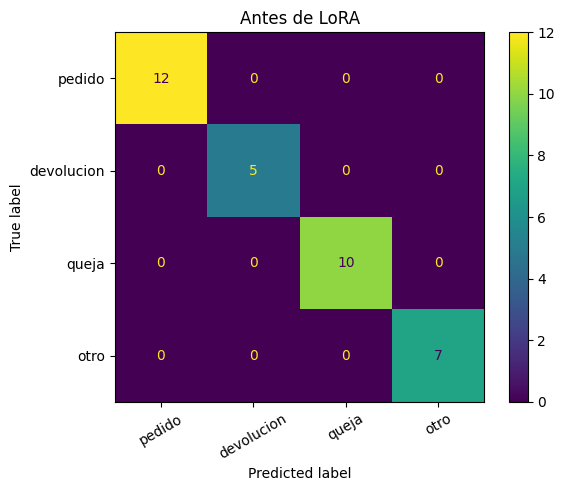

,mensaje,categoria,prediccion,correcto
7,"Hola, necesito gestionar lo siguiente: consult...",devolucion,sin_clasificar,False
31,"Por favor, indicadme los pasos para consultar ...",devolucion,sin_clasificar,False
41,"Necesito información, concretamente quiero pre...",otro,sin_clasificar,False
43,"Por favor, ¿me podéis indicar cómo puedo consu...",pedido,pedido,True
49,"Hola, necesito consultar si se puede modificar...",pedido,pedido,True
59,Necesito trasladar mi malestar: comunicar que ...,queja,queja,True
61,Una consulta: ¿podríais ayudarme a preguntar s...,otro,otro,True
63,"Buenas, ¿me podéis informar sobre esto? Quiero...",otro,otro,True
65,Os escribo para dejar constancia de que quiero...,queja,queja,True
77,Me gustaría resolver esto: necesito saber cuán...,devolucion,sin_clasificar,False


In [17]:
baseline_df, baseline_accuracy = evaluate_model(model, test_df, "Antes de LoRA")
baseline_df.to_csv("resultados_antes.csv", index=False)
display(baseline_df[["mensaje", "categoria", "prediccion", "correcto"]].head(10))

## 10. Preparar LoRA y tokenizar los 250 mensajes

Entrenaremos solo adaptadores LoRA. La pérdida se calcula sobre la etiqueta objetivo, no sobre el texto de la instrucción. Esto ayuda a centrar el ajuste en la clasificación.

In [19]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [20]:
from peft import LoraConfig, get_peft_model, TaskType
from torch.utils.data import Dataset
from transformers import Trainer, TrainingArguments, DataCollatorForSeq2Seq

MAX_LENGTH = 384

class ClassificationSFTDataset(Dataset):
    def __init__(self, frame, tokenizer):
        self.items = []
        for _, row in frame.iterrows():
            prompt = build_prompt(row["mensaje"]) + " "
            completion = row["categoria"] + tokenizer.eos_token
            prompt_ids = tokenizer(prompt, add_special_tokens=True)["input_ids"]
            completion_ids = tokenizer(completion, add_special_tokens=False)["input_ids"]
            input_ids = (prompt_ids + completion_ids)[:MAX_LENGTH]
            labels = ([-100] * len(prompt_ids) + completion_ids)[:MAX_LENGTH]
            self.items.append({
                "input_ids": input_ids,
                "attention_mask": [1] * len(input_ids),
                "labels": labels
            })
    def __len__(self):
        return len(self.items)
    def __getitem__(self, idx):
        return self.items[idx]

train_dataset = ClassificationSFTDataset(train_df, tokenizer)

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type=TaskType.CAUSAL_LM,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
)

model.enable_input_require_grads()
model.gradient_checkpointing_enable()
model.config.use_cache = False
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

trainable params: 9,232,384 || all params: 1,552,946,688 || trainable%: 0.5945


## 11. Entrenar

Configuración inicial conservadora para una GPU de Colab: micro-lote 2, acumulación 8, 3 épocas. Si aparece `CUDA out of memory`, reinicia el entorno y reduce `per_device_train_batch_size` a 1 y/o `MAX_LENGTH` a 256, reconstruyendo dataset y modelo desde cero.

In [22]:
collator = DataCollatorForSeq2Seq(
    tokenizer=tokenizer,
    model=model,
    padding=True,
    label_pad_token_id=-100,
    pad_to_multiple_of=8
)

training_args = TrainingArguments(
    output_dir="qwen-eventhub-lora",
    num_train_epochs=3,
    per_device_train_batch_size=2,
    gradient_accumulation_steps=8,
    learning_rate=2e-4,
    fp16=True,
    logging_steps=5,
    save_strategy="epoch",
    save_total_limit=2,
    report_to="none",
    optim="adamw_torch",
    weight_decay=0.01,
    lr_scheduler_type="cosine",
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    dataloader_pin_memory=True
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    data_collator=collator
)

train_result = trainer.train()
print(train_result)

Step,Training Loss
5,6.039105
10,0.352523
15,0.213348
20,0.027419
25,0.026032
30,0.050615
35,0.003496
40,0.002849
45,0.002690


TrainOutput(global_step=48, training_loss=0.6999373546859715, metrics={'train_runtime': 245.4829, 'train_samples_per_second': 3.055, 'train_steps_per_second': 0.196, 'total_flos': 795670844424192.0, 'train_loss': 0.6999373546859715, 'epoch': 3.0})


## 12. Evaluar después de LoRA

Volvemos a evaluar exactamente los mismos 50 mensajes. No se modifica el conjunto de prueba.

Después de LoRA — accuracy: 0.840 (42/50)
              precision    recall  f1-score   support

      pedido       1.00      0.87      0.93        15
  devolucion       0.65      1.00      0.79        15
       queja       1.00      0.90      0.95        10
        otro       1.00      0.50      0.67        10

    accuracy                           0.84        50
   macro avg       0.91      0.82      0.83        50
weighted avg       0.90      0.84      0.84        50



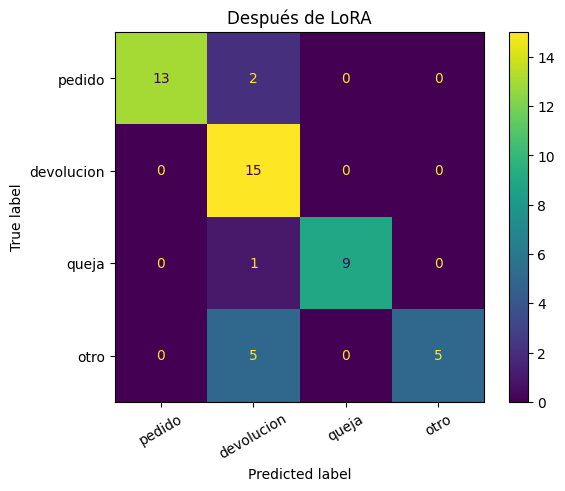

,Modelo,Aciertos,Total,Accuracy
0,Antes de LoRA,34,50,0.68
1,Después de LoRA,42,50,0.84


In [23]:
model.config.use_cache = True
model.eval()
after_df, after_accuracy = evaluate_model(model, test_df, "Después de LoRA")

after_df.to_csv("resultados_despues.csv", index=False)
comparison = pd.DataFrame([
    {"Modelo": "Antes de LoRA", "Aciertos": int(baseline_df["correcto"].sum()), "Total": 50, "Accuracy": baseline_accuracy},
    {"Modelo": "Después de LoRA", "Aciertos": int(after_df["correcto"].sum()), "Total": 50, "Accuracy": after_accuracy}
])
display(comparison)

## 13. Guardar resultados y adaptador

Se publicará el adaptador LoRA, no una copia completa de los pesos base. Quien lo descargue necesitará también el modelo base indicado en la ficha.

In [24]:
import json
from pathlib import Path

OUTPUT_DIR = "qwen-eventhub-lora"
model.save_pretrained(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

metrics = {
    "base_model": MODEL_ID,
    "test_examples": int(len(test_df)),
    "baseline_correct": int(baseline_df["correcto"].sum()),
    "baseline_accuracy": float(baseline_accuracy),
    "lora_correct": int(after_df["correcto"].sum()),
    "lora_accuracy": float(after_accuracy),
    "labels": LABELS,
    "train_examples": int(len(train_df))
}
with open("metricas_comparacion.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)
print(metrics)

{'base_model': 'Qwen/Qwen2.5-1.5B-Instruct', 'test_examples': 50, 'baseline_correct': 34, 'baseline_accuracy': 0.68, 'lora_correct': 42, 'lora_accuracy': 0.84, 'labels': ['pedido', 'devolucion', 'queja', 'otro'], 'train_examples': 250}


## 14. Publicar en Hugging Face Hub

Cambia `HF_USERNAME` por tu nombre de usuario de Hugging Face. El repositorio se creará público. El nombre debe ser único dentro de tu cuenta.

In [25]:
from huggingface_hub import login
from google.colab import userdata

HF_TOKEN = userdata.get("HF_TOKEN")
login(token=HF_TOKEN)

In [26]:
from huggingface_hub import HfApi, create_repo

HF_USERNAME = "javiz12188"  # <-- CAMBIAR
REPO_ID = f"{HF_USERNAME}/qwen2.5-1.5b-clasificador-clientes-lora"

if HF_USERNAME == "TU_USUARIO_HUGGINGFACE":
    raise ValueError("Sustituye HF_USERNAME por tu usuario real de Hugging Face.")

api = HfApi()
create_repo(repo_id=REPO_ID, repo_type="model", private=False, exist_ok=True)
model.push_to_hub(REPO_ID, token=HF_TOKEN)
tokenizer.push_to_hub(REPO_ID, token=HF_TOKEN)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:   0%|          | 23.2kB / 37.0MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mp7r_kl_62/tokenizer.json:   0%|          | 27.6kB / 11.4MB            

Validating                    :           |   0%            

CommitInfo(commit_url='https://huggingface.co/javiz12188/qwen2.5-1.5b-clasificador-clientes-lora/commit/77df07556ae29981e3c0048be80e41b8d88dfa00', commit_message='Upload tokenizer', commit_description='', oid='77df07556ae29981e3c0048be80e41b8d88dfa00', pr_url=None, repo_url=RepoUrl('https://huggingface.co/javiz12188/qwen2.5-1.5b-clasificador-clientes-lora', endpoint='https://huggingface.co', repo_type='model', repo_id='javiz12188/qwen2.5-1.5b-clasificador-clientes-lora'), pr_revision=None, pr_num=None)

### Crear la ficha del modelo (Model Card)

In [27]:
model_card = f'''---
license: apache-2.0
base_model: {MODEL_ID}
library_name: peft
tags:
- lora
- text-classification
- spanish
- customer-support
---

# Clasificador de mensajes de clientes en español

Adaptador LoRA de **{MODEL_ID}** para clasificar mensajes de atención al cliente en cuatro categorías:

- `pedido`
- `devolucion`
- `queja`
- `otro`

## Uso previsto
Proyecto educativo y demostración de ajuste fino eficiente con LoRA. No está validado para decisiones empresariales sin evaluación adicional.

## Entrenamiento
- Dataset sintético: 300 ejemplos, 75 por categoría.
- Entrenamiento: 250 ejemplos.
- Prueba reservada: 50 ejemplos.
- Técnica: LoRA (PEFT).
- Modelo base: [{MODEL_ID}](https://huggingface.co/{MODEL_ID}).

## Resultados en el conjunto de prueba
- Modelo base: {metrics['baseline_correct']}/50 ({metrics['baseline_accuracy']:.1%}).
- Modelo con LoRA: {metrics['lora_correct']}/50 ({metrics['lora_accuracy']:.1%}).

Los resultados corresponden únicamente al conjunto sintético utilizado en esta práctica y no garantizan el rendimiento con mensajes reales.

## Cargar el adaptador
```python
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel
import torch

base_id = "{MODEL_ID}"
adapter_id = "{REPO_ID}"
tokenizer = AutoTokenizer.from_pretrained(base_id)
base = AutoModelForCausalLM.from_pretrained(
    base_id, torch_dtype=torch.float16, device_map="auto"
)
model = PeftModel.from_pretrained(base, adapter_id)
```
'''
with open("README.md", "w", encoding="utf-8") as f:
    f.write(model_card)
api.upload_file(
    path_or_fileobj="README.md",
    path_in_repo="README.md",
    repo_id=REPO_ID,
    repo_type="model"
)
print("Modelo publicado:", f"https://huggingface.co/{REPO_ID}")

Modelo publicado: https://huggingface.co/javiz12188/qwen2.5-1.5b-clasificador-clientes-lora


## 15. Descargar evidencias para la entrega

Descarga el notebook desde **Archivo → Descargar → Descargar .ipynb**. También descarga los CSV y el JSON de resultados para conservar las evidencias de evaluación.

In [28]:
from google.colab import files
for filename in [
    "mensajes_clientes_300.csv",
    "resultados_antes.csv",
    "resultados_despues.csv",
    "metricas_comparacion.json",
    "README.md"
]:
    if os.path.exists(filename):
        files.download(filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Checklist final de entrega

- [ ] Notebook `.ipynb` con todas las celdas ejecutadas y sus salidas.
- [ ] GPU utilizada y registrada.
- [ ] 300 mensajes revisados: 75 por categoría.
- [ ] División 250 entrenamiento / 50 prueba, sin solapamiento.
- [ ] Resultado del modelo base sobre los 50 mensajes.
- [ ] Entrenamiento LoRA completado.
- [ ] Resultado del modelo ajustado sobre los mismos 50 mensajes.
- [ ] Comparación de aciertos y accuracy.
- [ ] Adaptador LoRA publicado en Hugging Face Hub.
- [ ] Model Card con descripción y resultados reales.
- [ ] Enlace público al repositorio del modelo.